# Интерпретация модели

Посмотрим, какие признаки влияют на прогноз XGBoost и где модель ошибается. Используем тот же final holdout и ту же модель, что в `05_final_evaluation.ipynb`.

SHAP объясняет поведение модели, но не доказывает причинную связь.

In [1]:
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder
from xgboost import DMatrix, XGBClassifier

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 50)

RANDOM_STATE = 42
TARGET = "isFraud"
ID_COLUMN = "TransactionID"
SECONDS_PER_DAY = 86_400
FINAL_N_ESTIMATORS = 1758
SHAP_SAMPLE_SIZE = 5_000

project_root = Path.cwd()
if not (project_root / "data").exists():
    project_root = project_root.parent
data_dir = project_root / "data"

## 1. Результаты модели

Сравним локальные метрики и Kaggle Score. Близость holdout и Private Score показывает, что временная валидация работает хорошо.

In [2]:
score_summary = pd.DataFrame(
    {
        "ROC-AUC": [0.90217, 0.90913, 0.911611, 0.937537],
        "role": [
            "selection during development",
            "untouched local temporal holdout",
            "final Kaggle estimate",
            "public leaderboard part",
        ],
    },
    index=["development_cv", "final_holdout", "kaggle_private", "kaggle_public"],
)
display(score_summary)

,ROC-AUC,role
development_cv,0.902170,selection during development
final_holdout,0.909130,untouched local temporal holdout
kaggle_private,0.911611,final Kaggle estimate
kaggle_public,0.937537,public leaderboard part


## 2. Данные

Загружаем признаки финальной модели и делим train по времени.

In [3]:
transaction_columns = [
    "TransactionID", "TransactionDT", "TransactionAmt", "ProductCD",
    "card1", "card2", "card3", "card4", "card5", "card6",
    "addr1", "addr2", "dist1", "dist2",
    "P_emaildomain", "R_emaildomain",
    *[f"C{i}" for i in range(1, 15)],
    *[f"D{i}" for i in range(1, 16)],
    *[f"M{i}" for i in range(1, 10)],
]

selected_v_columns = (
    "V281 V282 V283 V289 V296 V301 V314 V1 V3 V4 V6 V8 V11 V13 V14 V17 V20 "
    "V23 V26 V27 V30 V36 V37 V40 V41 V44 V47 V48 V54 V55 V56 V59 V62 V65 V67 "
    "V68 V70 V76 V78 V80 V82 V86 V88 V89 V91 V127 V98 V99 V107 V108 V109 V111 "
    "V114 V115 V117 V120 V121 V123 V129 V130 V131 V138 V139 V142 V147 V155 V162 "
    "V165 V160 V166 V203 V207 V173 V169 V171 V174 V175 V180 V185 V198 V210 V209 "
    "V264 V223 V240 V241 V260 V277 V220 V221 V234 V238 V250 V271 V307 V284 V285 "
    "V286 V291 V303 V305 V309 V310 V312 V320 V332 V325 V335"
).split()

model_transaction_columns = transaction_columns + selected_v_columns

categorical_columns = [
    "ProductCD", "card4", "card6", "P_emaildomain", "R_emaildomain",
    *[f"M{i}" for i in range(1, 10)],
    "id_12", "id_15", "id_16", "id_23", "id_27", "id_28",
    "id_29", "id_30", "id_31", "id_33", "id_34", "id_35",
    "id_36", "id_37", "id_38", "DeviceType", "DeviceInfo",
]

identity_columns = [
    *[f"id_{i:02d}" for i in range(1, 10)],
    *[f"id_{i}" for i in range(10, 39)],
]

dtypes = {
    column: "float32"
    for column in model_transaction_columns + identity_columns
}
dtypes.update({column: "category" for column in categorical_columns})
dtypes[ID_COLUMN] = "int32"
dtypes[TARGET] = "int8"

selected_d_columns = ["D1", "D2", "D4", "D10", "D11", "D15"]

In [4]:
transactions = pd.read_csv(
    data_dir / "train_transaction.csv",
    index_col=ID_COLUMN,
    usecols=model_transaction_columns + [TARGET],
    dtype=dtypes,
)
identity = pd.read_csv(
    data_dir / "train_identity.csv",
    index_col=ID_COLUMN,
    dtype=dtypes,
)

y = transactions.pop(TARGET)
X = transactions.join(identity, how="left")

del transactions, identity


print("Full train:", X.shape)
print("Fraud rate:", f"{y.mean():.2%}")

Full train: (590540, 201)
Fraud rate: 3.50%


In [5]:
relative_day = (X["TransactionDT"] // SECONDS_PER_DAY).astype("int16")

train_mask = relative_day.between(1, 122)
holdout_mask = relative_day.between(153, 182)

context_columns = [
    "TransactionDT", "TransactionAmt", "ProductCD", "card4",
    "card6", "P_emaildomain", "DeviceType",
]
holdout_context = X.loc[holdout_mask, context_columns].copy()
holdout_context["relative_day"] = relative_day.loc[holdout_mask]
holdout_context["has_identity"] = X.loc[holdout_mask, identity_columns].notna().any(axis=1)

split_summary = pd.DataFrame(
    {
        "rows": [int(train_mask.sum()), int(holdout_mask.sum())],
        "first_day": [
            int(relative_day.loc[train_mask].min()),
            int(relative_day.loc[holdout_mask].min()),
        ],
        "last_day": [
            int(relative_day.loc[train_mask].max()),
            int(relative_day.loc[holdout_mask].max()),
        ],
        "fraud_rate": [y.loc[train_mask].mean(), y.loc[holdout_mask].mean()],
    },
    index=["train", "final_holdout"],
)
display(split_summary.round(4))

,rows,first_day,last_day,fraud_rate
train,420066,1,122,0.0352
final_holdout,85430,153,182,0.0350


## 3. Подготовка и обучение

Повторяем feature engineering и обучаем encoder только на временном train.

In [6]:
def add_time_features(data):
    df = data.copy()

    df["hour"] = (df["TransactionDT"] // 3_600) % 24
    df["weekday"] = (df["TransactionDT"] // SECONDS_PER_DAY) % 7
    df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)
    df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)
    df["weekday_sin"] = np.sin(2 * np.pi * df["weekday"] / 7)
    df["weekday_cos"] = np.cos(2 * np.pi * df["weekday"] / 7)

    return df


def normalize_selected_d_features(data, columns=selected_d_columns):
    df = data.copy()
    transaction_day = df["TransactionDT"] / SECONDS_PER_DAY

    for column in columns:
        df[column] = (df[column] - transaction_day).astype("float32")

    return df


def build_features(data):
    return normalize_selected_d_features(add_time_features(data))

In [7]:
feature_started = perf_counter()

X_train_features = build_features(X.loc[train_mask])
X_holdout_features = build_features(X.loc[holdout_mask])
y_train = y.loc[train_mask].to_numpy(dtype=np.int8)
y_holdout = y.loc[holdout_mask].to_numpy(dtype=np.int8)
holdout_index = X.loc[holdout_mask].index.to_numpy()

categorical_model_columns = [
    column for column in categorical_columns
    if column in X_train_features.columns
]
numeric_model_columns = [
    column for column in X_train_features.columns
    if column not in categorical_model_columns
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OrdinalEncoder(
                handle_unknown="use_encoded_value",
                unknown_value=-1,
                encoded_missing_value=-2,
                dtype=np.float32,
            ),
            categorical_model_columns,
        ),
        ("numeric", "passthrough", numeric_model_columns),
    ],
    verbose_feature_names_out=False,
)

X_train_matrix = preprocessor.fit_transform(X_train_features).astype(
    np.float32, copy=False
)
X_holdout_matrix = preprocessor.transform(X_holdout_features).astype(
    np.float32, copy=False
)
feature_names = preprocessor.get_feature_names_out()


print("Train matrix:", X_train_matrix.shape)
print("Holdout matrix:", X_holdout_matrix.shape)
print(f"Feature preparation: {perf_counter() - feature_started:.1f}s")

del X_train_features, X_holdout_features, X, y

Train matrix: (420066, 207)
Holdout matrix: (85430, 207)
Feature preparation: 2.5s


In [8]:
selected_params = {
    "n_estimators": FINAL_N_ESTIMATORS,
    "learning_rate": 0.015442878662368152,
    "max_depth": 7,
    "min_child_weight": 3.3973837770378004,
    "subsample": 0.8549473812230148,
    "colsample_bytree": 0.7161707124793311,
    "gamma": 0.06801678402593356,
    "reg_alpha": 0.002929317375402625,
    "reg_lambda": 14.622376387551679,
    "eval_metric": "auc",
    "tree_method": "hist",
    "max_bin": 256,
    "verbosity": 0,
    "n_jobs": -1,
    "random_state": RANDOM_STATE,
}

model = XGBClassifier(**selected_params)

fit_started = perf_counter()
model.fit(X_train_matrix, y_train, verbose=False)
fit_seconds = perf_counter() - fit_started

holdout_proba = model.predict_proba(X_holdout_matrix)[:, 1]
holdout_roc_auc = roc_auc_score(y_holdout, holdout_proba)
holdout_pr_auc = average_precision_score(y_holdout, holdout_proba)

print(f"Fit time: {fit_seconds / 60:.1f} min")
print(f"Holdout ROC-AUC: {holdout_roc_auc:.5f}")
print(f"Holdout PR-AUC:  {holdout_pr_auc:.5f}")

Fit time: 0.9 min
Holdout ROC-AUC: 0.90913
Holdout PR-AUC:  0.55475


## 4. Feature importance

Gain показывает пользу признаков в разбиениях деревьев, но не показывает направление влияния.

,gain
C4,478.8015
V264,227.8320
id_12,218.6146
C8,180.5328
C7,151.0550
V283,135.9773
V70,134.0845
C1,113.1749
C14,110.1356
V198,98.4599


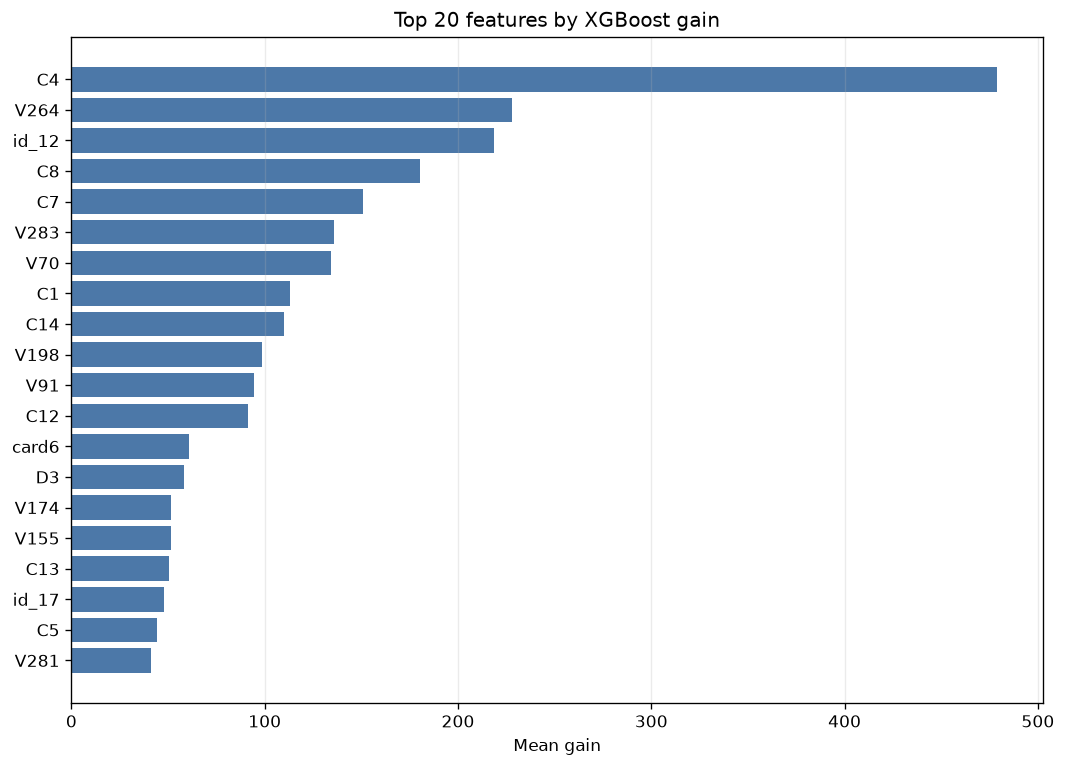

In [9]:
gain_scores = model.get_booster().get_score(importance_type="gain")

gain_importance = pd.Series(
    {
        feature_names[int(feature_key[1:])]: score
        for feature_key, score in gain_scores.items()
    },
    name="gain",
).sort_values(ascending=False)

top_gain = gain_importance.head(20).sort_values()

fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(top_gain.index, top_gain.values, color="#4C78A8")
ax.set(
    xlabel="Mean gain",
    title="Top 20 features by XGBoost gain",
)
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

display(gain_importance.head(20).to_frame().round(4))

## 5. SHAP

Считаем TreeSHAP для 5000 строк holdout. Положительный SHAP повышает fraud score, отрицательный — понижает. Значения измеряются в log-odds.

In [10]:
all_holdout_positions = np.arange(len(y_holdout))
shap_positions, _ = train_test_split(
    all_holdout_positions,
    train_size=SHAP_SAMPLE_SIZE,
    stratify=y_holdout,
    random_state=RANDOM_STATE,
)

X_shap = X_holdout_matrix[shap_positions]
y_shap = y_holdout[shap_positions]

shap_started = perf_counter()
shap_output = model.get_booster().predict(
    DMatrix(X_shap),
    pred_contribs=True,
    approx_contribs=False,
)
shap_seconds = perf_counter() - shap_started

shap_values = shap_output[:, :-1]
shap_base_value = shap_output[:, -1]
reconstructed_margin = shap_values.sum(axis=1) + shap_base_value
model_margin = model.predict(X_shap, output_margin=True)


print("SHAP sample:", X_shap.shape)
print("Frauds in sample:", int(y_shap.sum()))
print(f"SHAP calculation: {shap_seconds:.1f}s")
print("Maximum margin reconstruction error:", f"{np.max(np.abs(reconstructed_margin - model_margin)):.2e}")

SHAP sample: (5000, 207)
Frauds in sample: 175
SHAP calculation: 4.7s
Maximum margin reconstruction error: 1.96e-05


,mean_abs_shap,gain,shap_rank,gain_rank
C13,0.2589,50.4012,1,17
TransactionAmt,0.2257,13.1820,2,79
C1,0.1987,113.1749,3,8
card6,0.1976,60.9642,4,13
C14,0.1622,110.1356,5,9
D4,0.1429,10.5198,6,117
D3,0.1241,58.1911,7,14
V70,0.1194,134.0845,8,7
C5,0.1191,44.5298,9,19
D1,0.1142,17.6163,10,60


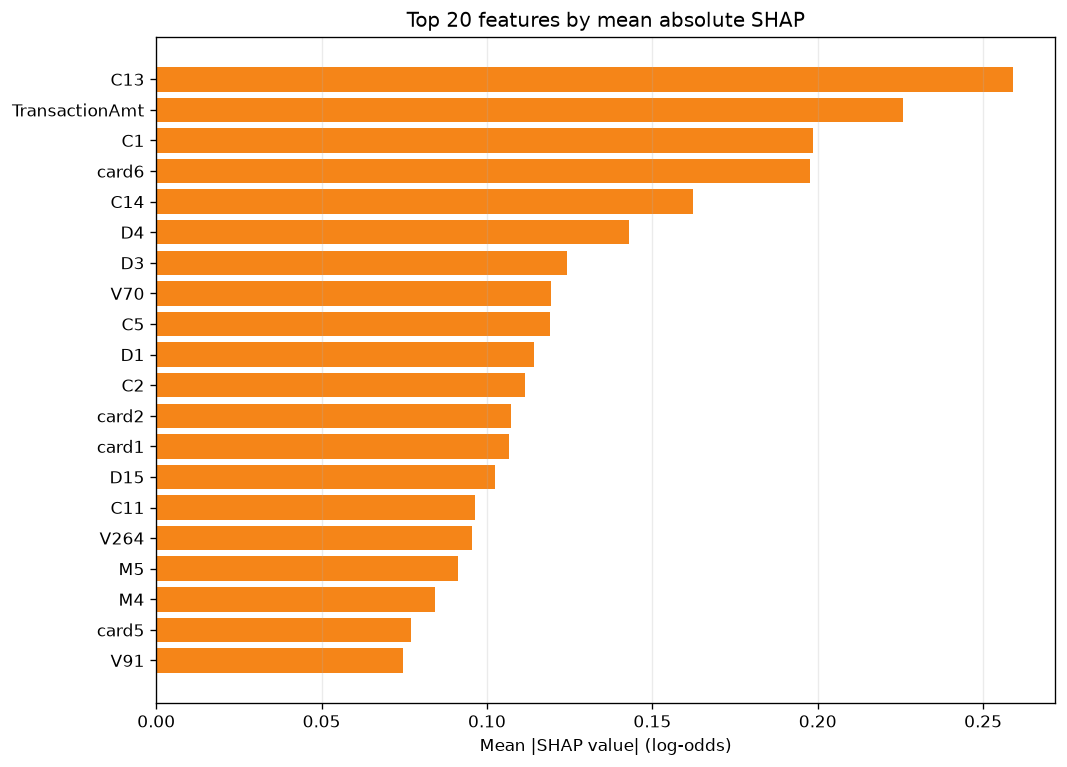

In [11]:
shap_importance = pd.Series(
    np.abs(shap_values).mean(axis=0),
    index=feature_names,
    name="mean_abs_shap",
).sort_values(ascending=False)

importance_comparison = pd.concat(
    [shap_importance, gain_importance],
    axis=1,
).fillna(0)
importance_comparison["shap_rank"] = (
    importance_comparison["mean_abs_shap"]
    .rank(ascending=False, method="min")
    .astype(int)
)
importance_comparison["gain_rank"] = (
    importance_comparison["gain"]
    .rank(ascending=False, method="min")
    .astype(int)
)

top_shap = shap_importance.head(20).sort_values()

fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(top_shap.index, top_shap.values, color="#F58518")
ax.set(
    xlabel="Mean |SHAP value| (log-odds)",
    title="Top 20 features by mean absolute SHAP",
)
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

display(
    importance_comparison
    .sort_values("mean_abs_shap", ascending=False)
    .head(20)
    .round(4)
)

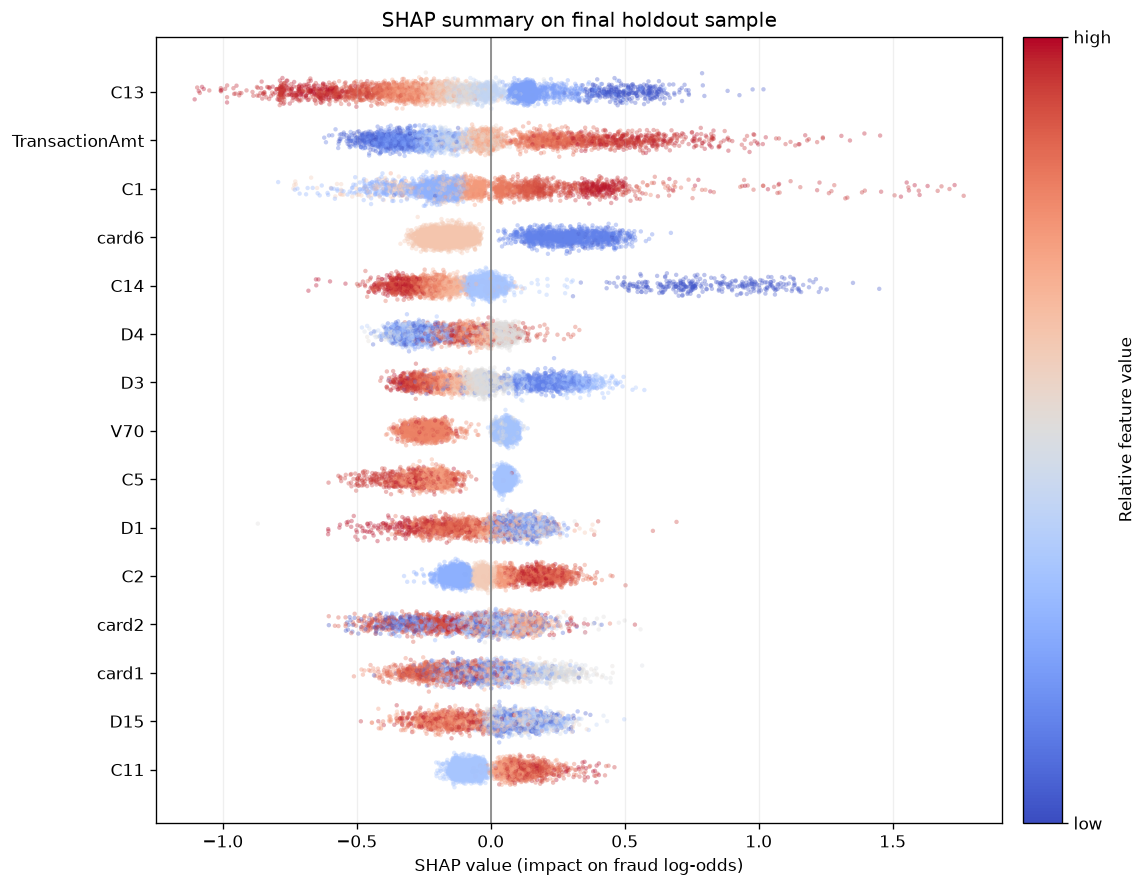

In [12]:
top_beeswarm_features = shap_importance.head(15).index.tolist()
feature_to_position = {
    feature: position for position, feature in enumerate(feature_names)
}
rng = np.random.default_rng(RANDOM_STATE)

fig, ax = plt.subplots(figsize=(10, 7.5))

for row, feature in enumerate(reversed(top_beeswarm_features)):
    position = feature_to_position[feature]
    feature_values = X_shap[:, position]
    contributions = shap_values[:, position]

    finite_mask = np.isfinite(feature_values)
    value_ranks = np.full(len(feature_values), 0.5)
    if finite_mask.any():
        value_ranks[finite_mask] = pd.Series(
            feature_values[finite_mask]
        ).rank(pct=True).to_numpy()

    jitter = rng.normal(0, 0.10, len(contributions))
    ax.scatter(
        contributions,
        row + jitter,
        c=value_ranks,
        cmap="coolwarm",
        vmin=0,
        vmax=1,
        s=7,
        alpha=0.35,
        linewidths=0,
        rasterized=True,
    )

ax.axvline(0, color="grey", linewidth=1)
ax.set_yticks(range(len(top_beeswarm_features)))
ax.set_yticklabels(list(reversed(top_beeswarm_features)))
ax.set(
    xlabel="SHAP value (impact on fraud log-odds)",
    title="SHAP summary on final holdout sample",
)
ax.grid(axis="x", alpha=0.2)

colorbar = fig.colorbar(
    plt.cm.ScalarMappable(cmap="coolwarm", norm=plt.Normalize(0, 1)),
    ax=ax,
    pad=0.02,
)
colorbar.set_ticks([0, 1])
colorbar.set_ticklabels(["low", "high"])
colorbar.set_label("Relative feature value")

plt.tight_layout()
plt.show()

Цвет показывает относительное значение признака. Для категорий после `OrdinalEncoder` порядок кодов условный, поэтому цвет нужно трактовать осторожно.

## 6. Примеры отдельных прогнозов

Разберём найденный fraud, ложный алерт и пропущенный fraud среди top 5% score.

In [13]:
alert_count = int(np.ceil(len(holdout_proba) * 0.05))
ranked_positions = np.argsort(-holdout_proba)
alert_mask = np.zeros(len(holdout_proba), dtype=bool)
alert_mask[ranked_positions[:alert_count]] = True

true_positive_positions = np.flatnonzero((y_holdout == 1) & alert_mask)
false_positive_positions = np.flatnonzero((y_holdout == 0) & alert_mask)
false_negative_positions = np.flatnonzero((y_holdout == 1) & ~alert_mask)

case_positions = {
    "true_positive": true_positive_positions[
        np.argmax(holdout_proba[true_positive_positions])
    ],
    "false_positive": false_positive_positions[
        np.argmax(holdout_proba[false_positive_positions])
    ],
    "false_negative": false_negative_positions[
        np.argmin(holdout_proba[false_negative_positions])
    ],
}

case_names = list(case_positions)
case_matrix = X_holdout_matrix[list(case_positions.values())]
case_shap_output = model.get_booster().predict(
    DMatrix(case_matrix),
    pred_contribs=True,
    approx_contribs=False,
)
case_shap_values = case_shap_output[:, :-1]

local_rows = []
for case_number, case_name in enumerate(case_names):
    position = case_positions[case_name]
    contribution = case_shap_values[case_number]
    strongest = np.argsort(np.abs(contribution))[-8:][::-1]

    for rank, feature_position in enumerate(strongest, start=1):
        local_rows.append(
            {
                "case": case_name,
                "TransactionID": holdout_index[position],
                "fraud_probability": holdout_proba[position],
                "rank": rank,
                "feature": feature_names[feature_position],
                "feature_value": case_matrix[case_number, feature_position],
                "shap_value": contribution[feature_position],
            }
        )

local_explanations = pd.DataFrame(local_rows)
display(local_explanations.round(4))

,case,TransactionID,fraud_probability,rank,feature,feature_value,shap_value
0,true_positive,3556658,0.9978,1,C14,0.000000,1.0376
1,true_positive,3556658,0.9978,2,C1,5.000000,0.9233
2,true_positive,3556658,0.9978,3,C13,0.000000,0.8338
3,true_positive,3556658,0.9978,4,TransactionAmt,300.000000,0.8287
4,true_positive,3556658,0.9978,5,V198,4.000000,0.7283
5,true_positive,3556658,0.9978,6,V155,4.000000,0.6145
6,true_positive,3556658,0.9978,7,V264,900.000000,0.5594
7,true_positive,3556658,0.9978,8,R_emaildomain,16.000000,0.4249
8,false_positive,3569342,0.9737,1,C14,0.000000,1.2136
9,false_positive,3569342,0.9737,2,C1,5.000000,0.6459


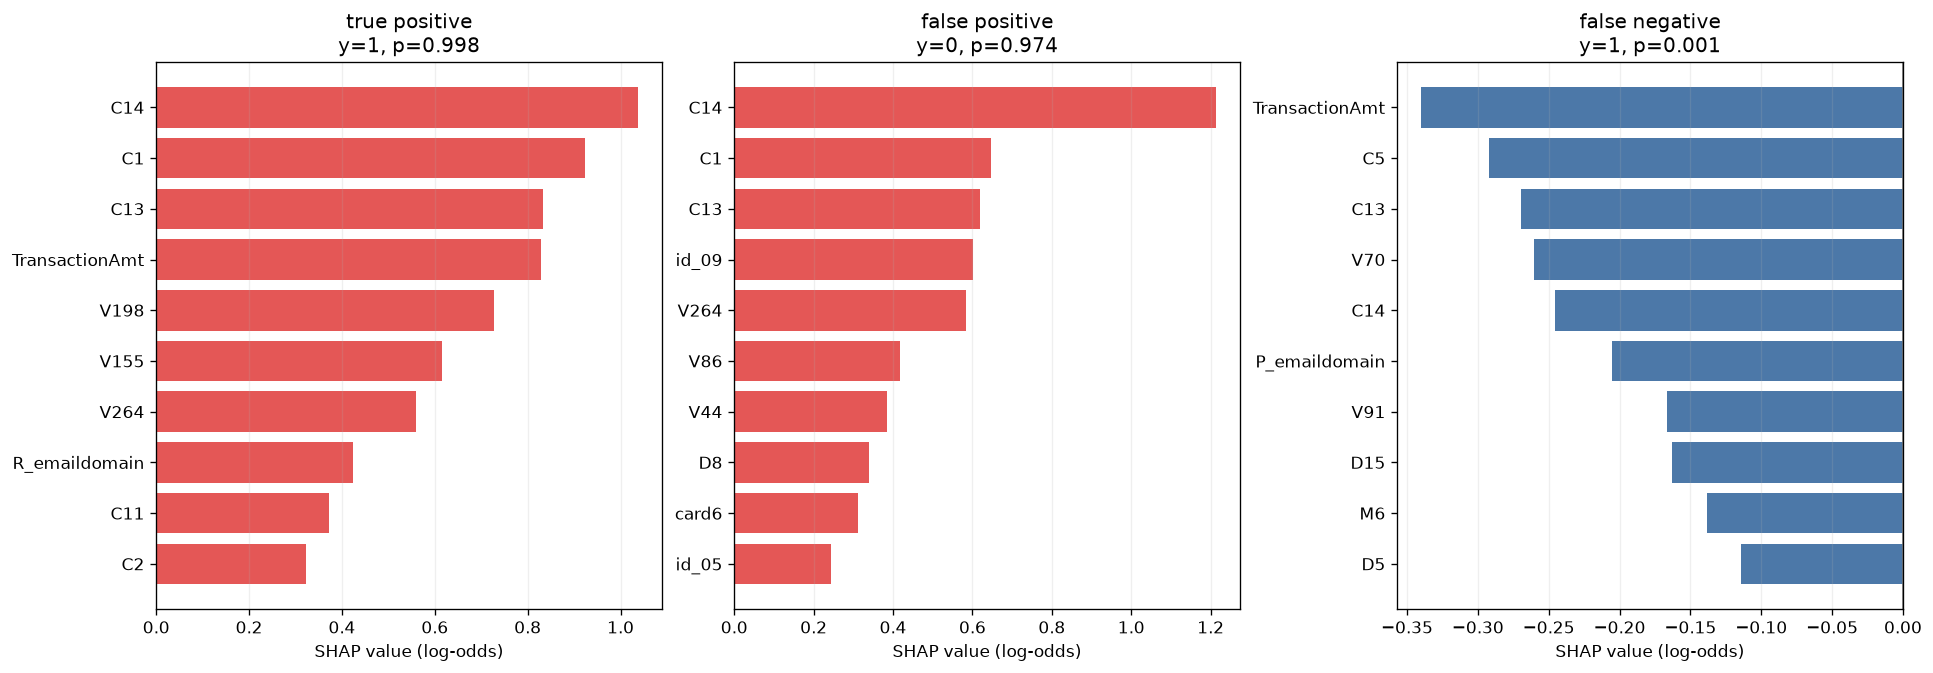

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5.5), constrained_layout=True)

for case_number, (ax, case_name) in enumerate(zip(axes, case_names)):
    contribution = case_shap_values[case_number]
    strongest = np.argsort(np.abs(contribution))[-10:]
    colors = np.where(contribution[strongest] >= 0, "#E45756", "#4C78A8")
    position = case_positions[case_name]

    ax.barh(
        feature_names[strongest],
        contribution[strongest],
        color=colors,
    )
    ax.axvline(0, color="grey", linewidth=1)
    ax.set_title(
        f"{case_name.replace('_', ' ')}\n"
        f"y={y_holdout[position]}, p={holdout_proba[position]:.3f}"
    )
    ax.set_xlabel("SHAP value (log-odds)")
    ax.grid(axis="x", alpha=0.2)

plt.show()

## 7. Ошибки по сегментам

Top 5% используем как пример ограниченного числа алертов.

In [15]:
tp = int(((y_holdout == 1) & alert_mask).sum())
fp = int(((y_holdout == 0) & alert_mask).sum())
fn = int(((y_holdout == 1) & ~alert_mask).sum())
tn = int(((y_holdout == 0) & ~alert_mask).sum())

top_five_summary = pd.Series(
    {
        "transactions": len(y_holdout),
        "alerts": int(alert_mask.sum()),
        "alert_rate": alert_mask.mean(),
        "true_positives": tp,
        "false_positives": fp,
        "false_negatives": fn,
        "true_negatives": tn,
        "precision": tp / (tp + fp),
        "fraud_capture_rate": tp / (tp + fn),
        "lift_vs_random": (tp / (tp + fp)) / y_holdout.mean(),
    },
    name="top_5_percent",
)
display(top_five_summary.to_frame().round(4))

,top_5_percent
transactions,85430.0000
alerts,4272.0000
alert_rate,0.0500
true_positives,1766.0000
false_positives,2506.0000
false_negatives,1228.0000
true_negatives,79930.0000
precision,0.4134
fraud_capture_rate,0.5898
lift_vs_random,11.7955


In [16]:
def segment_report(segment, target, probability, min_rows=500):
    frame = pd.DataFrame(
        {
            "segment": pd.Series(segment).astype("object").fillna("missing"),
            "target": target,
            "probability": probability,
        }
    )

    rows = []
    for segment_value, group in frame.groupby("segment", dropna=False):
        if len(group) < min_rows:
            continue

        segment_auc = np.nan
        if group["target"].nunique() == 2:
            segment_auc = roc_auc_score(group["target"], group["probability"])

        rows.append(
            {
                "segment": segment_value,
                "rows": len(group),
                "frauds": int(group["target"].sum()),
                "fraud_rate": group["target"].mean(),
                "mean_score": group["probability"].mean(),
                "roc_auc": segment_auc,
            }
        )

    return (
        pd.DataFrame(rows)
        .sort_values("rows", ascending=False)
        .set_index("segment")
    )


product_report = segment_report(
    holdout_context["ProductCD"].to_numpy(),
    y_holdout,
    holdout_proba,
)
device_report = segment_report(
    holdout_context["DeviceType"].to_numpy(),
    y_holdout,
    holdout_proba,
)
identity_report = segment_report(
    holdout_context["has_identity"].to_numpy(),
    y_holdout,
    holdout_proba,
)

print("ProductCD segments")
display(product_report.round(4))
print("DeviceType segments")
display(device_report.round(4))
print("Identity availability")
display(identity_report.round(4))

ProductCD segments
DeviceType segments
Identity availability


,rows,frauds,fraud_rate,mean_score,roc_auc
segment,,,,,
W,66743,1255,0.0188,0.0184,0.8630
C,9191,1252,0.1362,0.1200,0.9271
R,4094,202,0.0493,0.0580,0.9676
S,2913,132,0.0453,0.0343,0.8765
H,2489,153,0.0615,0.0641,0.8763


,rows,frauds,fraud_rate,mean_score,roc_auc
segment,,,,,
missing,67644,1314,0.0194,0.0188,0.8663
desktop,10210,777,0.0761,0.0760,0.9421
mobile,7576,903,0.1192,0.1027,0.9136


,rows,frauds,fraud_rate,mean_score,roc_auc
segment,,,,,
False,67169,1279,0.0190,0.0187,0.8641
True,18261,1715,0.0939,0.0861,0.9301


In [17]:
error_examples = holdout_context.copy()
error_examples["isFraud"] = y_holdout
error_examples["fraud_probability"] = holdout_proba
error_examples["error_type"] = "correct"
error_examples.loc[(y_holdout == 0) & alert_mask, "error_type"] = "false_positive"
error_examples.loc[(y_holdout == 1) & ~alert_mask, "error_type"] = "false_negative"

strongest_false_positives = (
    error_examples.query("error_type == 'false_positive'")
    .nlargest(10, "fraud_probability")
)
strongest_false_negatives = (
    error_examples.query("error_type == 'false_negative'")
    .nsmallest(10, "fraud_probability")
)

print("Highest-scored false positives")
display(strongest_false_positives)
print("Lowest-scored false negatives")
display(strongest_false_negatives)

Highest-scored false positives
Lowest-scored false negatives


,TransactionDT,TransactionAmt,ProductCD,card4,card6,P_emaildomain,DeviceType,relative_day,has_identity,isFraud,fraud_probability,error_type
TransactionID,,,,,,,,,,,,
3569342,15550017.0,78.387001,C,mastercard,credit,gmail.com,desktop,179,True,0,0.973748,false_positive
3551698,14952765.0,76.542999,C,visa,credit,gmail.com,mobile,173,True,0,0.965956,false_positive
3569699,15559262.0,130.645004,C,mastercard,credit,gmail.com,desktop,180,True,0,0.965389,false_positive
3569136,15545468.0,31.847000,C,visa,credit,gmail.com,mobile,179,True,0,0.959073,false_positive
3569645,15557752.0,130.645004,C,visa,credit,gmail.com,desktop,180,True,0,0.958548,false_positive
3525598,14209120.0,15.247000,C,visa,credit,gmail.com,mobile,164,True,0,0.952856,false_positive
3525595,14209019.0,15.247000,C,visa,credit,gmail.com,mobile,164,True,0,0.951751,false_positive
3525594,14208944.0,15.247000,C,visa,credit,gmail.com,mobile,164,True,0,0.951641,false_positive
3538620,14579555.0,33.077000,C,mastercard,credit,gmail.com,desktop,168,True,0,0.949581,false_positive


,TransactionDT,TransactionAmt,ProductCD,card4,card6,P_emaildomain,DeviceType,relative_day,has_identity,isFraud,fraud_probability,error_type
TransactionID,,,,,,,,,,,,
3546931,14837130.0,25.950001,W,mastercard,debit,att.net,NaN,171,False,1,0.001144,false_negative
3572872,15685940.0,25.950001,W,mastercard,debit,att.net,NaN,181,False,1,0.001227,false_negative
3506897,13644797.0,25.950001,W,mastercard,debit,att.net,NaN,157,False,1,0.001354,false_negative
3516141,13914551.0,50.000000,H,visa,credit,gmail.com,mobile,161,True,1,0.001480,false_negative
3536703,14511241.0,57.950001,W,mastercard,debit,yahoo.com,NaN,167,False,1,0.001512,false_negative
3577368,15807677.0,100.000000,H,american express,credit,hotmail.com,mobile,182,True,1,0.001620,false_negative
3521879,14080680.0,57.950001,W,mastercard,debit,yahoo.com,NaN,162,False,1,0.001656,false_negative
3545412,14773573.0,26.950001,W,visa,debit,yahoo.com,NaN,170,False,1,0.001867,false_negative
3533761,14426512.0,27.000000,W,visa,debit,gmail.com,NaN,166,False,1,0.001892,false_negative


## 8. Выводы

- По SHAP важнее всего `C13`, `TransactionAmt`, `C1`, `card6`, `C14`, `D4` и `D3`.
- Gain и SHAP дают разный порядок: например, `C4` первый по gain, а `TransactionAmt` второй по SHAP.
- В top 5% попадает 58.98% fraud. Precision равен 41.34%, lift — 11.80.
- Слабее всего модель работает для `ProductCD=W` и транзакций без identity.
- Уверенные false negatives часто имеют небольшую сумму, debit-карту и не содержат identity.

Следующее возможное улучшение — отдельно исследовать `ProductCD=W` и транзакции без identity.